# Sample representativeness of the UK cities on H3 hexagons (levels 8 and 7): panel users vs census population

Same check as `representation.ipynb` (Supplementary Material B of Marin-Flores, Dey, Zhang, Arcaute & Tenkanen 2026), for the five British cities,
with **H3 hexagons** as the unit instead of the 1 km / 2 km squares of the European reference grid. The Eurostat Census 2021 grid has no UK
cells; instead of putting the UK census onto squares and the hexagons onto those squares, the census is aggregated directly to hexagons.
Two resolutions are reported: **level 8** (0.65 km² at UK latitude, somewhat finer than the 1 km square) and **level 7** (4.6 km², close to the
2 km square that is the headline unit for the German and French cities).

1. **population per hexagon** = sum of the usual resident population of the census Output Areas (OA) whose centroid falls in the hexagon,
   assigned separately at each resolution. OAs are much smaller than the hexagons (median 0.03–0.06 km² in the city polygons, 12–23 OAs per
   level-8 hexagon there), so the centroid assignment loses little. Sources, all official and census-based:
   - England and Wales: ONS Census 2021 (21 March 2021), table TS001 (usual residents) per OA 2021, with the centroid of the generalised OA
     boundary (ONS Open Geography `OA_2021_EW_BGC_V2`; the ONS population-weighted-centroid layer is not reachable from Roihu, the difference is
     tens of metres for OAs this small);
   - Scotland: NRS Census 2022 (20 March 2022), usual resident population per OA 2022 with the NRS population-weighted centroids;
   - built once by hand into `boundaries/uk_oa/uk_oa_population_centroids.parquet` (235,243 OAs, 65.0 M residents, one row per OA with lon/lat).
2. **users per hexagon** = panel users whose **home cell** is the hexagon. The home cell is found at level 8 with the same rule and thresholds as
   the city notebooks (two-month rule, one record per user), from the level-8 user-day tables; for level 7 the level-8 home cells are rolled up
   to their parent hexagon, so the set of users is identical at both resolutions.
3. users vs population per hexagon on log–log axes with the fitted line, R² and slope, for all hexagons with users and population and for
   hexagons with at least `POP_MIN` residents and `USERS_MIN` users; the R² a proportional Poisson sample of the same size would reach;
   penetration (users / population) overall and per hexagon.

Hexagons of a city = cells of the given level whose centre is inside the Urban Audit 2020 FUA. Hexagons with no OA centroid are dropped (no
population information), as squares outside the census file are dropped in the grid version. Nothing is reweighted. For the German and French
cities the square-grid results of `representation.ipynb` stay as they are; each unit should be read against its own Poisson ceiling.


In [1]:
import os, time
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, h3, duckdb
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ---- parameters -------------------------------------------------------------
ALL_CITY_KEYS = ["london", "manchester", "birmingham", "glasgow", "liverpool"]
CITY_KEYS = [k for k in os.environ.get("LOCO_CITIES", ",".join(ALL_CITY_KEYS)).split(",") if k]
PERIOD    = "2024-05_2024-06"
H3_RES_HOME = 8                     # resolution of the user-day tables and of the home-cell rule (as in the city notebooks)
UNITS     = [8, 7]                  # units of analysis (must be <= H3_RES_HOME): level 8 ~0.65 km², level 7 ~4.6 km² at UK latitude
H_MIN, W_MIN = 10, 4                # same thresholds as the city notebooks
POP_MIN, USERS_MIN = 10, 2          # cells kept for the filtered fit and the penetration (as in representation.ipynb)
FIGURE_DPI = 150
assert all(r <= H3_RES_HOME for r in UNITS)

# same city table as the city notebooks (Urban Audit 2020 codes, UK bank holidays 6 and 27 May 2024, none in June)
CITIES = {
    "london":     dict(country="GBR", name="London",     fua="UK001L3", holidays={"2024-05": [6, 27], "2024-06": []}),
    "manchester": dict(country="GBR", name="Manchester", fua="UK008L3", holidays={"2024-05": [6, 27], "2024-06": []}),
    "birmingham": dict(country="GBR", name="Birmingham", fua="UK002L3", holidays={"2024-05": [6, 27], "2024-06": []}),
    "glasgow":    dict(country="GBR", name="Glasgow",    fua="UK004L1", holidays={"2024-05": [6, 27], "2024-06": []}),
    "liverpool":  dict(country="GBR", name="Liverpool",  fua="UK006L3", holidays={"2024-05": [6, 27], "2024-06": []}),
}
MONTHS = PERIOD.split("_")
NIGHT_HOURS = [22, 23, 0, 1, 2, 3, 4, 5, 6]; WORK_HOURS = [9, 10, 11, 12, 13, 14, 15, 16]; WORKDAYS = [1, 2, 3, 4, 5]
SCRATCH = Path(f"/scratch/project_2022768/{os.environ['USER']}/locomizer")
POP_OA = SCRATCH / "boundaries" / "uk_oa" / "uk_oa_population_centroids.parquet"    # one row per census OA: oa, lon, lat, population, source
POP_SOURCE = "ONS Census 2021 / NRS Census 2022 OAs -> H3"
def unit_label(res): return f"H3 level {res}"

fua_gdf = gpd.read_file(SCRATCH / "boundaries" / "URAU_RG_100K_2020_4326_FUA.geojson").set_index("URAU_CODE")   # 2020 = last edition with UK polygons
oa = pd.read_parquet(POP_OA)
POP_HEX = {}                                                                          # res -> population and number of OAs per hexagon
for res in UNITS:
    cell = [h3.latlng_to_cell(la, lo, res) for la, lo in zip(oa.lat.values, oa.lon.values)]
    POP_HEX[res] = oa.assign(cell=cell).groupby("cell").agg(population=("population", "sum"), n_oa=("oa", "size"))
    print(f"level {res}: {len(POP_HEX[res]):,} populated hexagons in Great Britain, {int(POP_HEX[res].population.sum()):,} residents from {len(oa):,} OAs")


level 8: 61,286 populated hexagons in Great Britain, 65,038,031 residents from 235,243 OAs


level 7: 24,668 populated hexagons in Great Britain, 65,038,031 residents from 235,243 OAs


## 1. Home cell per user (level 8)

Same rule as the city notebooks, applied to the level-8 user-day tables: home per month = cell with most night signals, work per month = other cell with most working-hour signals on working days; one record per user, the latest month in which both qualify, otherwise the latest month in which home qualifies. Users with `home_days >= H_MIN` are kept if their home cell lies in a hexagon of the city at any of the resolutions in `UNITS` (the level-7 hexagons of the FUA cover slightly more ground than the level-8 ones).


In [2]:
NIGHT = " + ".join(f"h{h}" for h in NIGHT_HOURS); WORK = " + ".join(f"h{h}" for h in WORK_HOURS)
# DuckDB spill files: on a full node (LOCO_LOCAL_WORK=1, 600 GiB node-local disk) use $TMPDIR, otherwise scratch
tmp_dir = Path(os.environ["TMPDIR"]) / "duck_tmp_representation" if os.environ.get("LOCO_LOCAL_WORK") == "1" else SCRATCH / "results" / "duck_tmp_representation"
mem_gb = int(os.environ.get("SLURM_MEM_PER_NODE", "16000")) // 1000

def users_per_home_cell(key):
    """users per level-8 home cell for one city, and the hexagons of the city at each resolution in UNITS"""
    c = CITIES[key]; FUA = fua_gdf.loc[c["fua"]].geometry
    units = {res: sorted(h3.geo_to_cells(FUA, res)) for res in UNITS}                 # cells whose centre is inside the FUA
    keep = set()                                                                       # level-8 cells belonging to a unit of any resolution
    for res, cells in units.items():
        keep.update(cells if res == H3_RES_HOME else (ch for cell in cells for ch in h3.cell_to_children(cell, H3_RES_HOME)))
    holiday_sql = " OR ".join(f"(month = '{m}' AND day IN ({', '.join(map(str, d))}))" for m, d in c["holidays"].items() if d) or "false"
    wd = f"dow IN ({', '.join(map(str, WORKDAYS))}) AND NOT ({holiday_sql})"
    con = duckdb.connect()
    con.execute(f"SET threads = {int(os.environ.get('SLURM_CPUS_PER_TASK', os.cpu_count()))}; SET memory_limit = '{int(mem_gb * 0.8)}GB'; "
                f"SET temp_directory = '{tmp_dir}'; SET preserve_insertion_order = false; SET enable_progress_bar = false;")
    con.execute("CREATE VIEW ud AS " + " UNION ALL ".join(
        f"SELECT '{m}' AS month, * FROM read_parquet('{SCRATCH}/{c['country']}_userday_h3_{H3_RES_HOME}_{m}/userday.parquet')" for m in MONTHS))
    con.execute(f"""CREATE TABLE home AS SELECT userid, month, h3_8 AS home_cell, home_days FROM (
        SELECT userid, month, h3_8, count(*) AS home_days,
               row_number() OVER (PARTITION BY userid, month ORDER BY sum(n_night) DESC, sum(n_total) DESC, h3_8) AS rn
        FROM (SELECT userid, month, h3_8, n_total, ({NIGHT}) AS n_night FROM ud) WHERE n_night > 0 GROUP BY userid, month, h3_8) WHERE rn = 1""")
    con.execute(f"""CREATE TABLE work AS SELECT userid, month, work_days FROM (
        SELECT u.userid, u.month, u.h3_8, count(*) AS work_days,
               row_number() OVER (PARTITION BY u.userid, u.month ORDER BY sum(u.n_work) DESC, sum(u.n_total) DESC, u.h3_8) AS rn
        FROM (SELECT userid, month, day, h3_8, n_total, ({WORK}) AS n_work FROM ud WHERE {wd}) u JOIN home h USING (userid, month)
        WHERE u.h3_8 <> h.home_cell AND u.n_work > 0 GROUP BY u.userid, u.month, u.h3_8) WHERE rn = 1""")
    fua_cells = pd.DataFrame({"home_cell": sorted(keep)}); con.register("fua_cells", fua_cells)
    out = con.execute(f"""
        SELECT home_cell, count(*) AS users FROM (
            SELECT h.userid, h.home_cell, h.home_days,
                   row_number() OVER (PARTITION BY h.userid ORDER BY coalesce(h.home_days >= {H_MIN} AND w.work_days >= {W_MIN}, false) DESC,
                                                                 coalesce(h.home_days >= {H_MIN}, false) DESC, h.month DESC) AS rn
            FROM home h LEFT JOIN work w USING (userid, month)
        ) WHERE rn = 1 AND home_days >= {H_MIN} AND home_cell IN (SELECT home_cell FROM fua_cells)
        GROUP BY home_cell""").df()
    con.close()
    return out, units

HOMES = {}
for key in CITY_KEYS:
    t0 = time.time(); HOMES[key] = users_per_home_cell(key)
    print(f"{CITIES[key]['name']:<10} {int(HOMES[key][0].users.sum()):>8,} users with a home in the FUA, in {len(HOMES[key][0]):>6,} level-{H3_RES_HOME} cells; "
          + ", ".join(f"{len(cells):,} level-{res} hexagons" for res, cells in HOMES[key][1].items()) + f" ({time.time()-t0:.0f} s)")


London     1,277,203 users with a home in the FUA, in  6,928 level-8 cells; 10,580 level-8 hexagons, 1,507 level-7 hexagons (547 s)


Manchester  327,955 users with a home in the FUA, in  2,436 level-8 cells; 4,709 level-8 hexagons, 668 level-7 hexagons (521 s)


Birmingham  303,544 users with a home in the FUA, in  2,018 level-8 cells; 3,234 level-8 hexagons, 460 level-7 hexagons (440 s)


Glasgow     131,972 users with a home in the FUA, in  1,486 level-8 cells; 5,219 level-8 hexagons, 743 level-7 hexagons (520 s)


Liverpool   134,727 users with a home in the FUA, in  1,009 level-8 cells; 1,500 level-8 hexagons, 218 level-7 hexagons (465 s)


## 2. Users and census population per hexagon

One row per hexagon of the FUA (at each resolution) that contains at least one OA centroid; `users_home_count` = panel users with their home there (level-8 home cells rolled up to the parent for level 7), `population` = census residents of the OAs whose centroid is there, `n_oa` = number of those OAs, `area_km2` = the hexagon's area.


In [3]:
def hex_table(key, res):
    homes, units = HOMES[key]
    cell = homes.home_cell if res == H3_RES_HOME else homes.home_cell.map(lambda h: h3.cell_to_parent(h, res))
    users = homes.assign(cell=cell).groupby("cell").users.sum().rename("users_home_count")
    g = pd.DataFrame({"cell": units[res]}).join(users, on="cell").fillna({"users_home_count": 0})
    g = g.join(POP_HEX[res], on="cell", how="inner")              # hexagons without an OA centroid are dropped (no population information)
    g["population"] = g.population.astype(int); g["users_home_count"] = g.users_home_count.astype(int); g["n_oa"] = g.n_oa.astype(int)
    g["area_km2"] = g.cell.map(lambda h: h3.cell_area(h, "km^2"))
    return g

G = {(key, res): hex_table(key, res) for key in CITY_KEYS for res in UNITS}
for res in UNITS:
    for key in CITY_KEYS:
        g = G[(key, res)]
        print(f"level {res} {CITIES[key]['name']:<10} census population {g.population.sum():>12,} | sample users {g.users_home_count.sum():>8,} | "
              f"hexagons with users {int((g.users_home_count > 0).sum()):>6,} / {len(g):,} | mean area {g.area_km2.mean():.2f} km² | OAs per hexagon median {g.n_oa.median():.0f}")


level 8 London     census population   12,366,348 | sample users 1,230,667 | hexagons with users  4,906 / 5,492 | mean area 0.66 km² | OAs per hexagon median 4
level 8 Manchester census population    3,423,655 | sample users  320,454 | hexagons with users  1,894 / 2,190 | mean area 0.66 km² | OAs per hexagon median 4
level 8 Birmingham census population    3,136,409 | sample users  295,117 | hexagons with users  1,553 / 1,748 | mean area 0.66 km² | OAs per hexagon median 5
level 8 Glasgow    census population    1,839,683 | sample users  129,747 | hexagons with users  1,224 / 1,390 | mean area 0.64 km² | OAs per hexagon median 8
level 8 Liverpool  census population    1,537,674 | sample users  129,464 | hexagons with users    794 / 903 | mean area 0.66 km² | OAs per hexagon median 4
level 7 London     census population   12,408,627 | sample users 1,262,729 | hexagons with users  1,334 / 1,353 | mean area 4.60 km² | OAs per hexagon median 8
level 7 Manchester census population    3,402,

## 3. Hexagon population vs. sample users (log–log)

One figure per city and resolution. Left: all hexagons with at least one user and one resident. Right: hexagons with at least `POP_MIN` residents and `USERS_MIN` users. Red line = least-squares fit of log10(population) on log10(users).


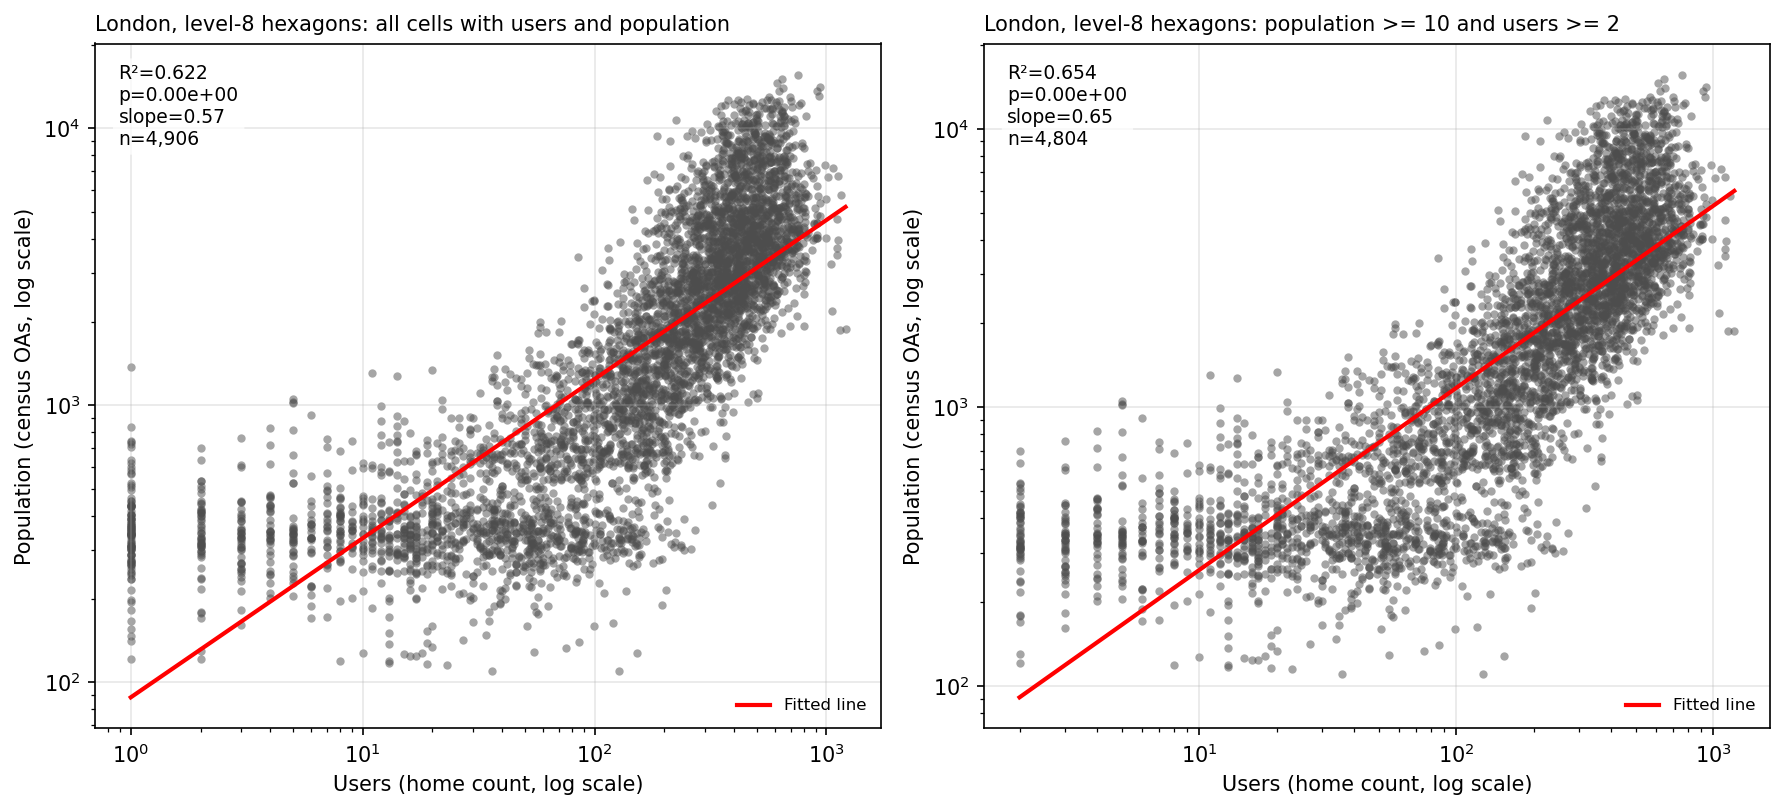

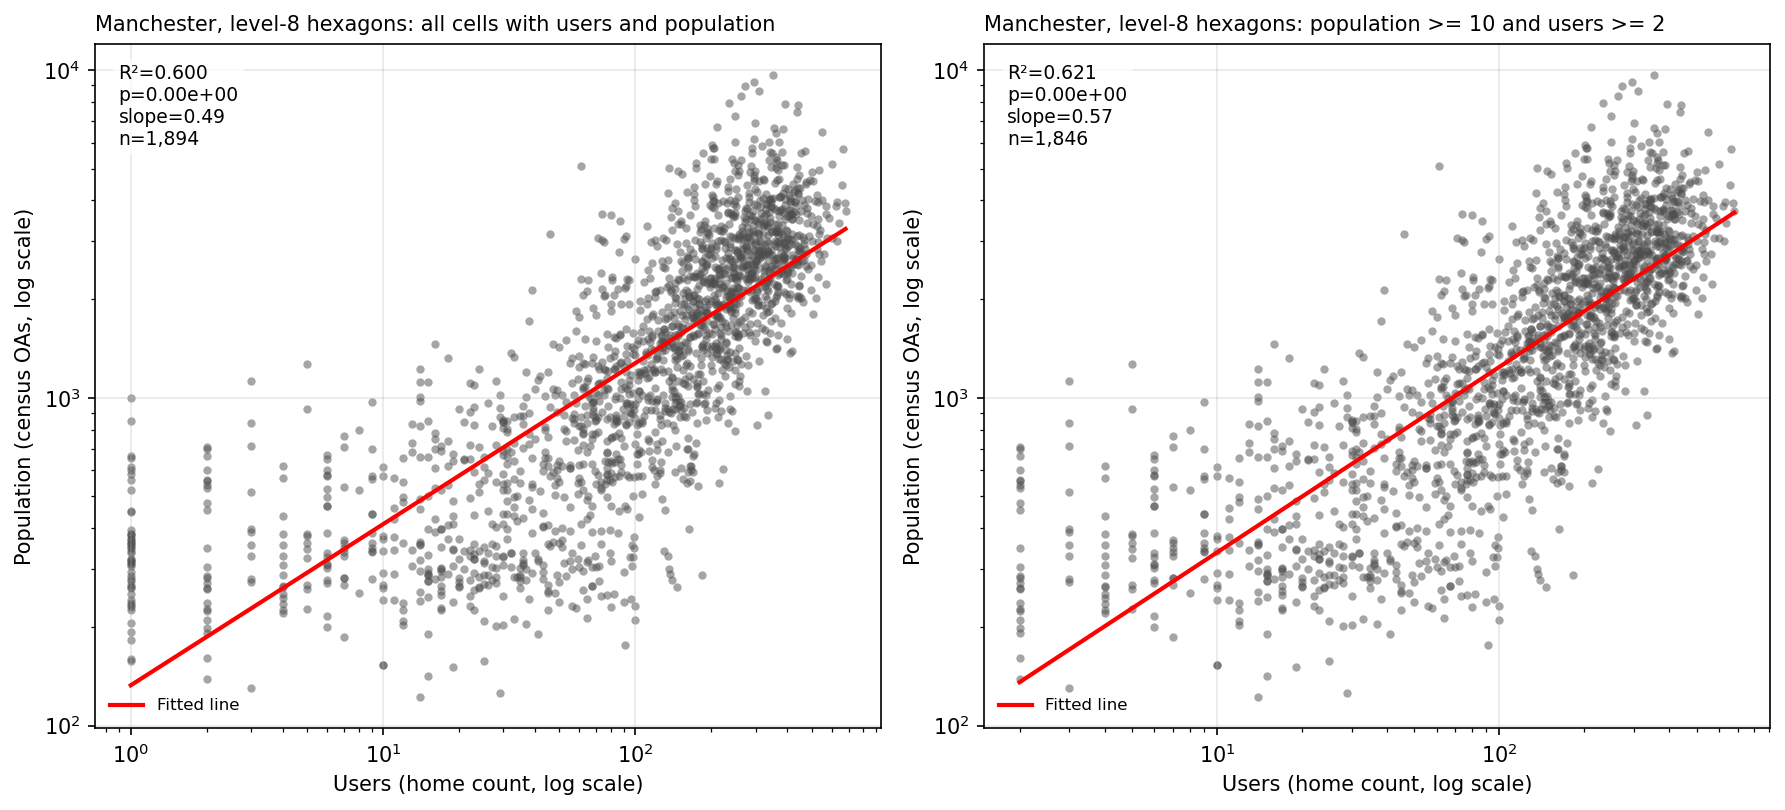

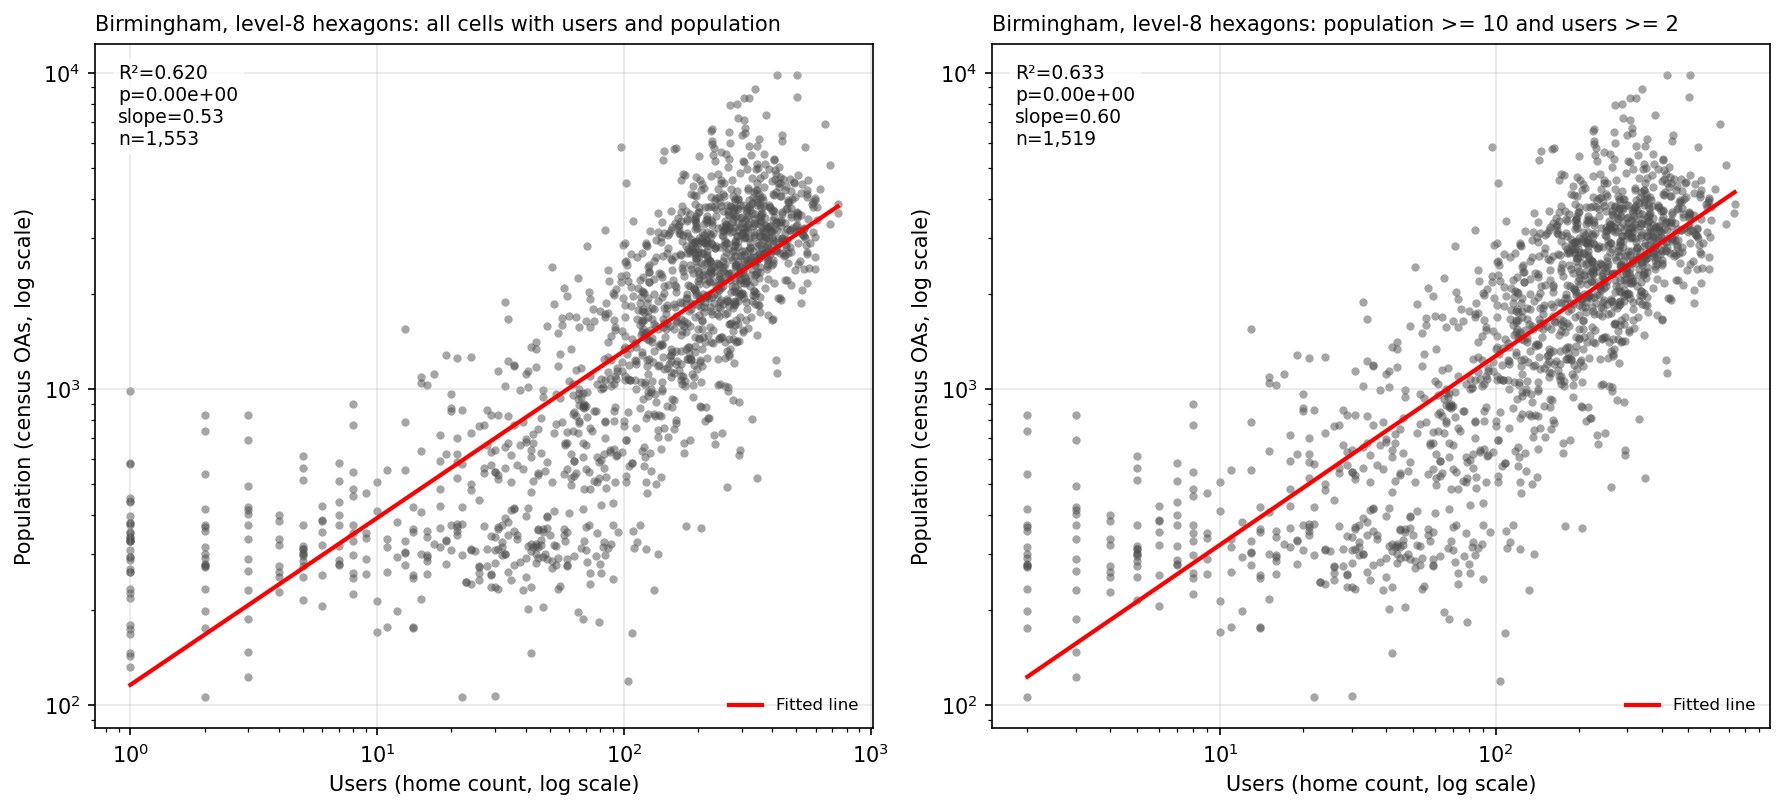

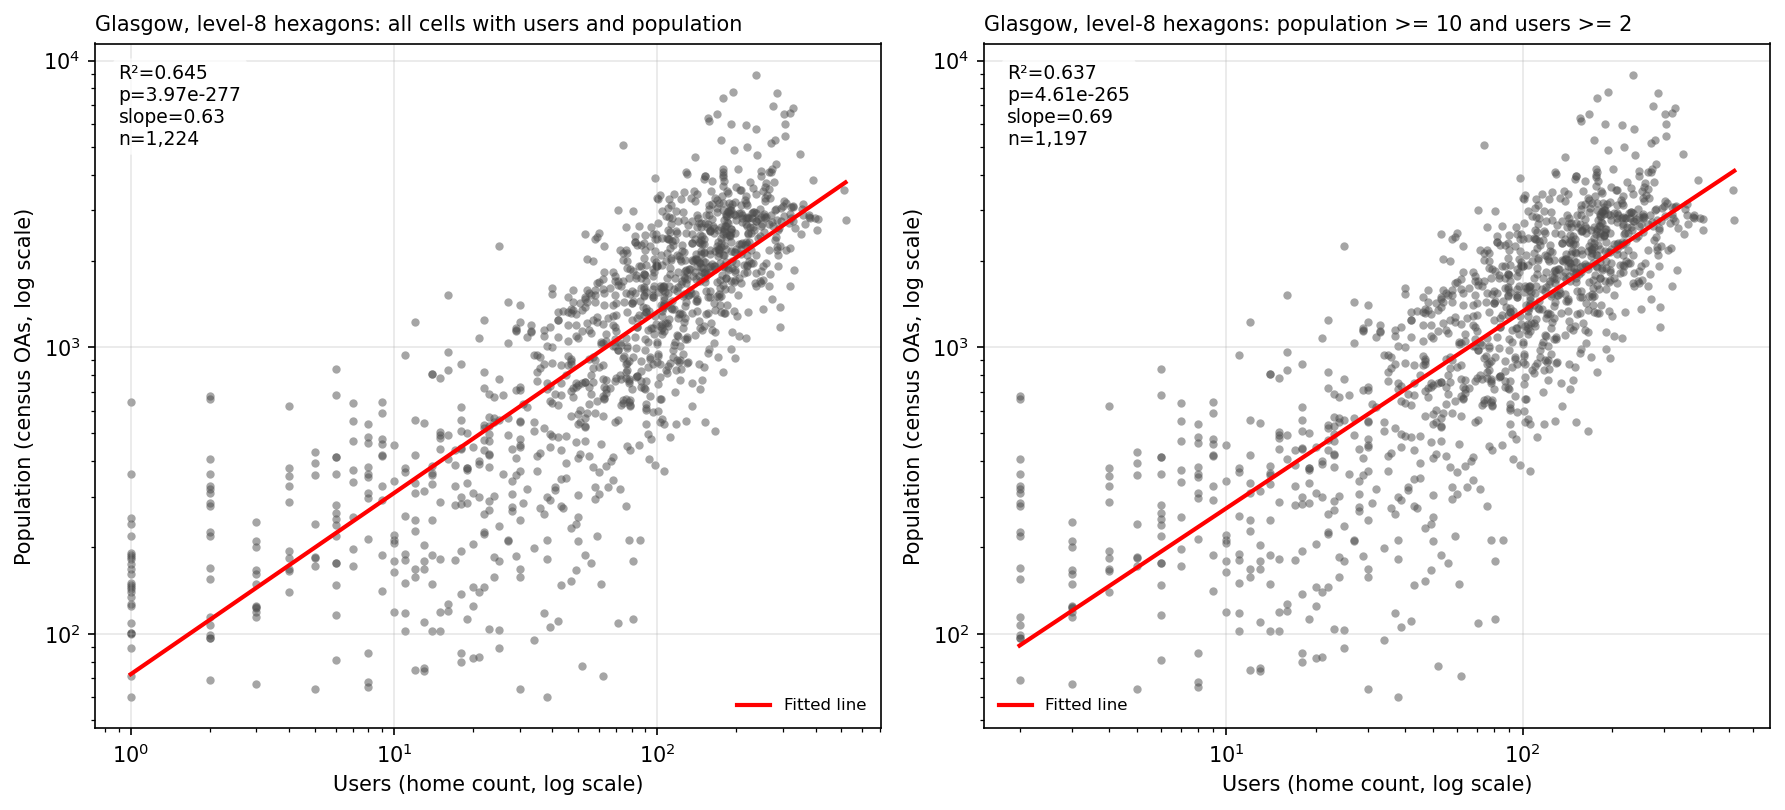

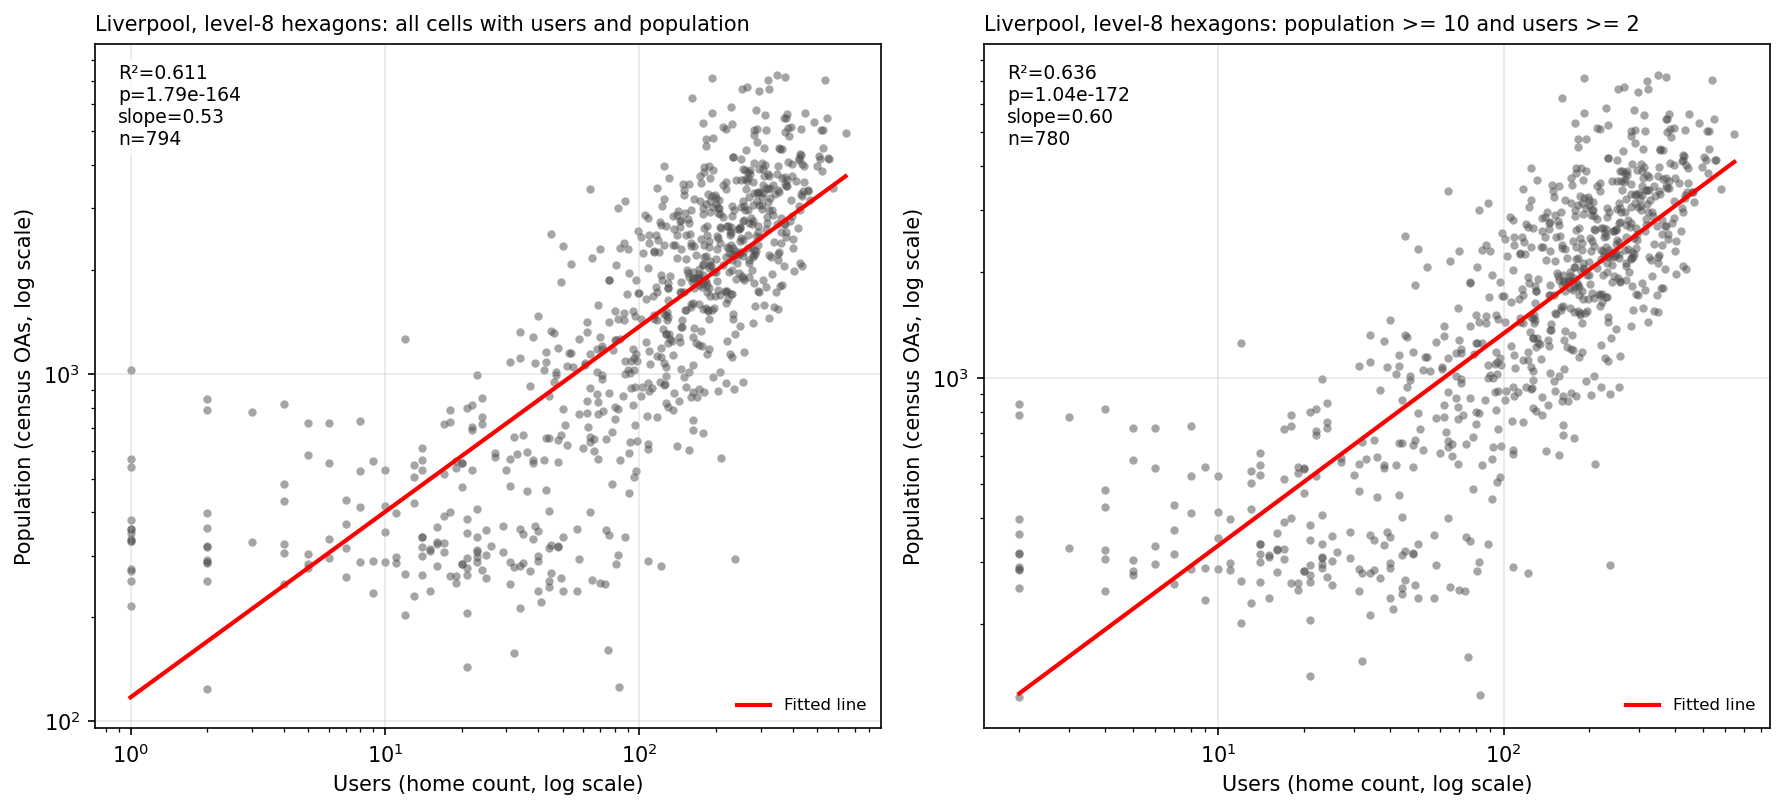

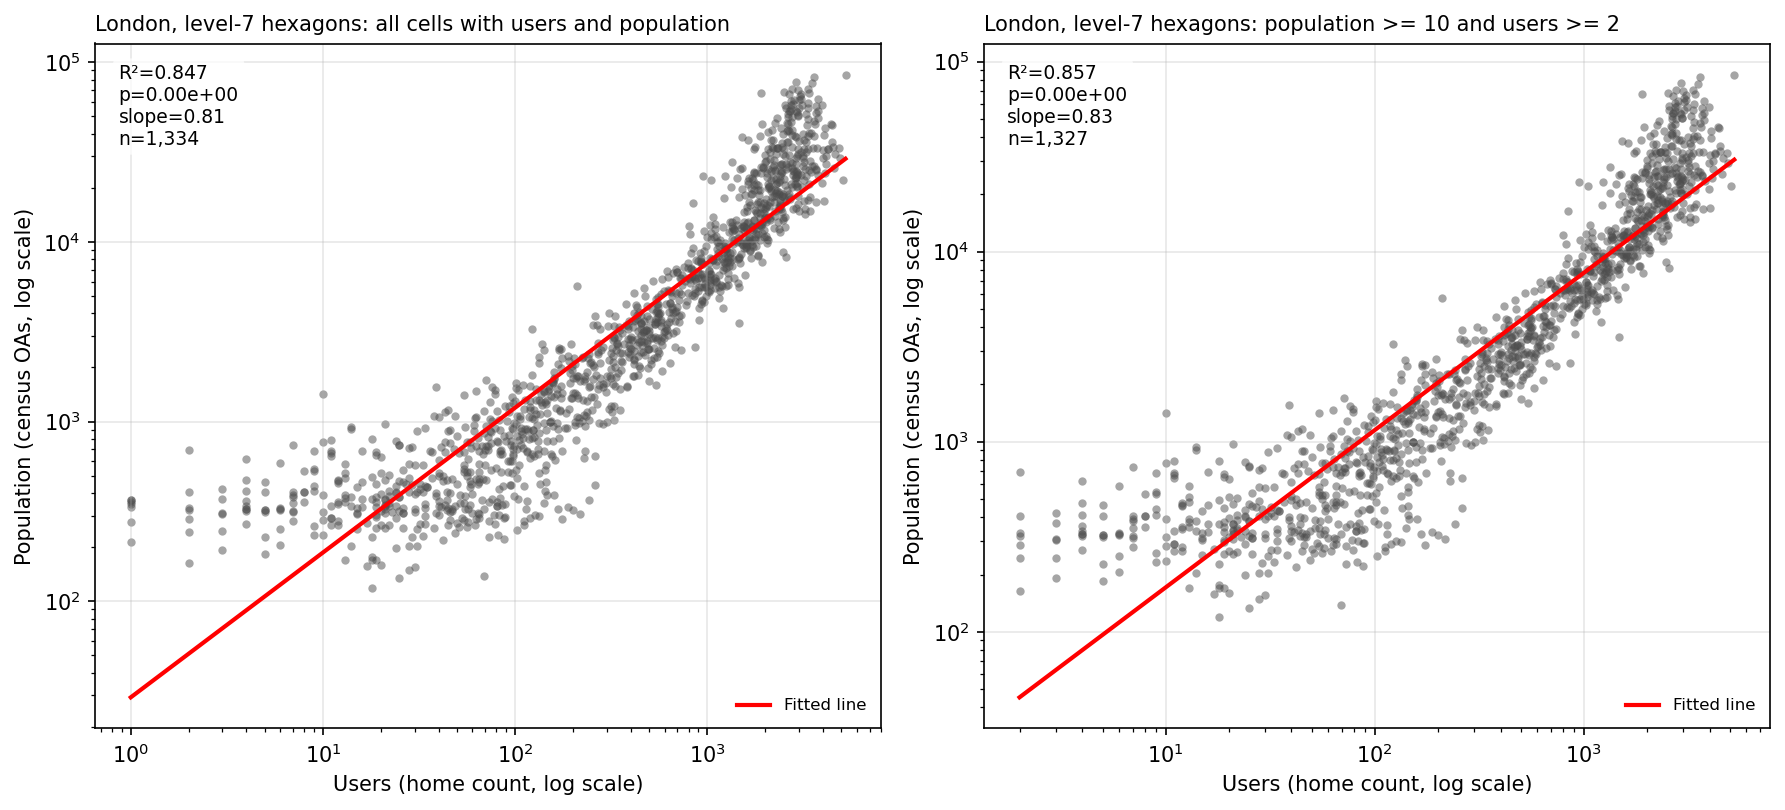

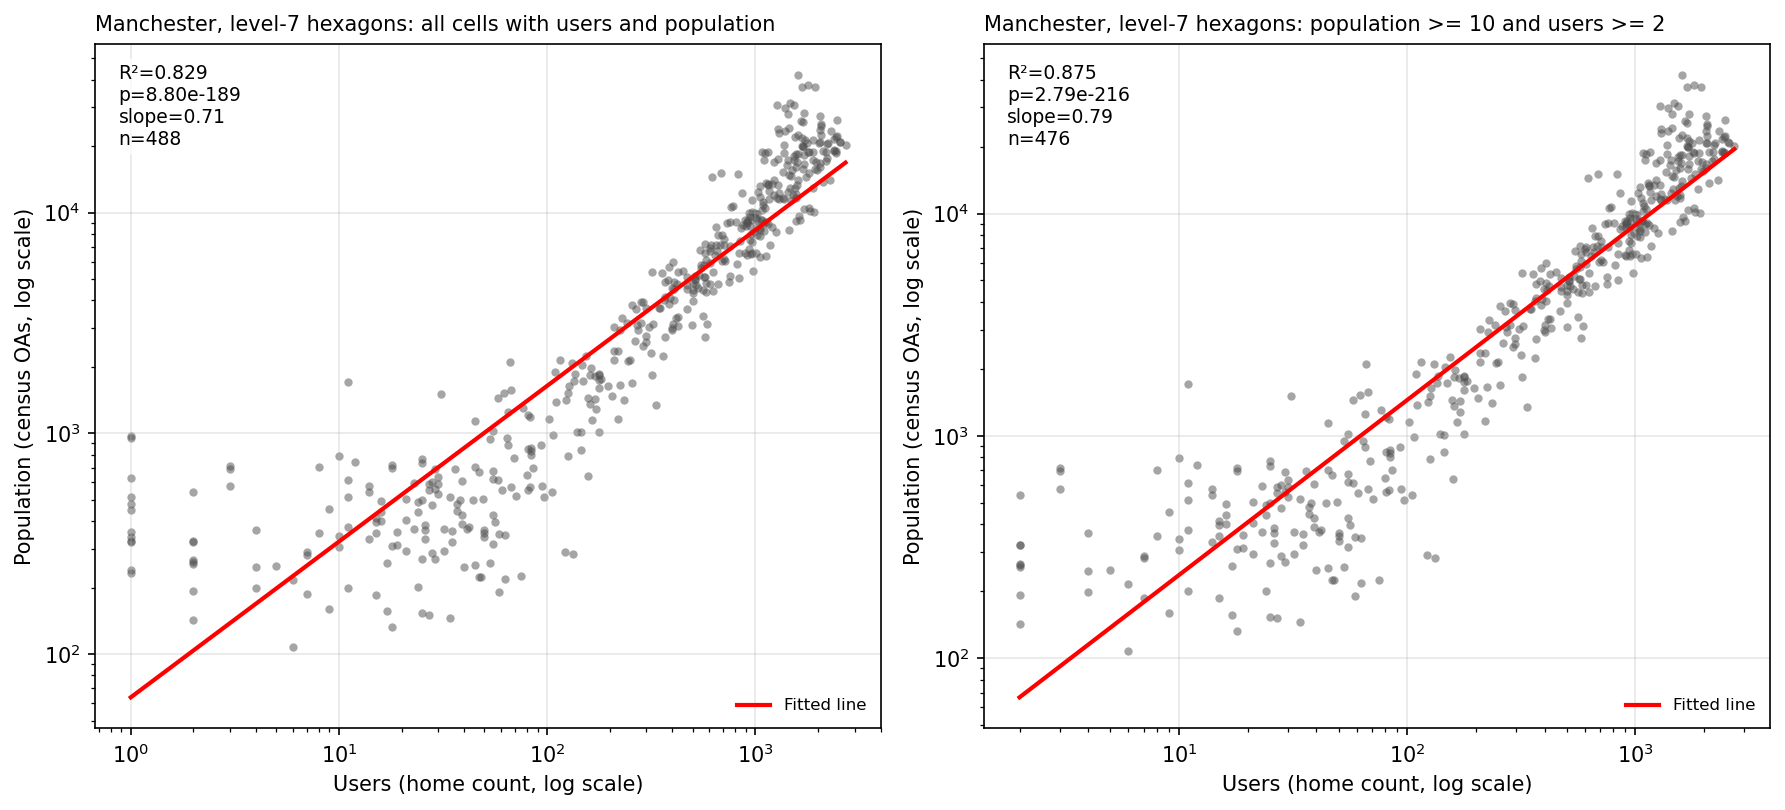

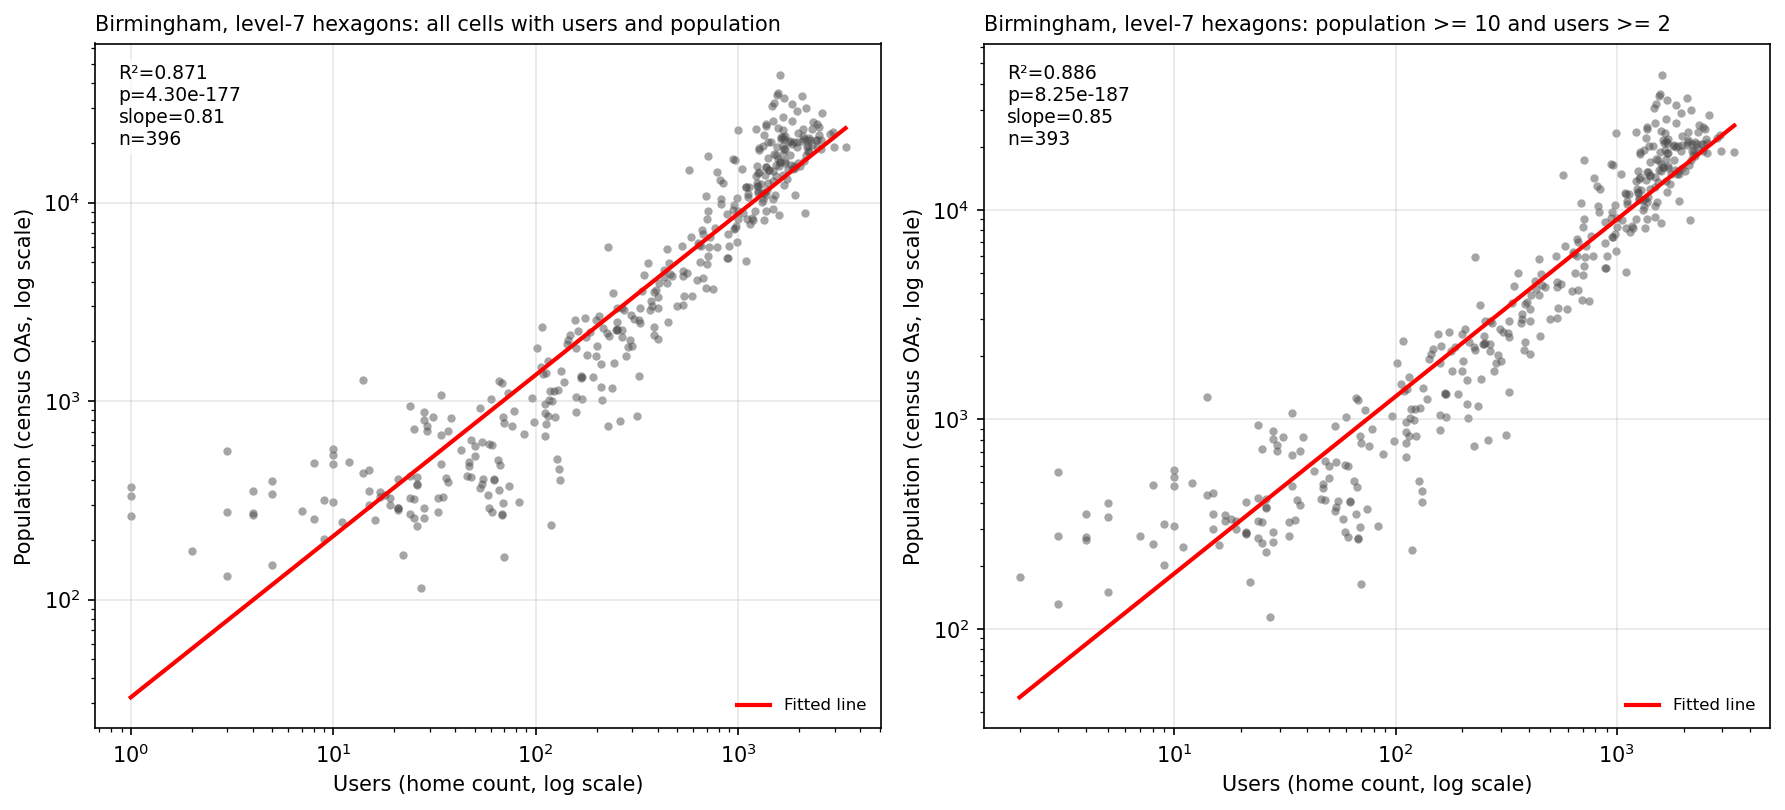

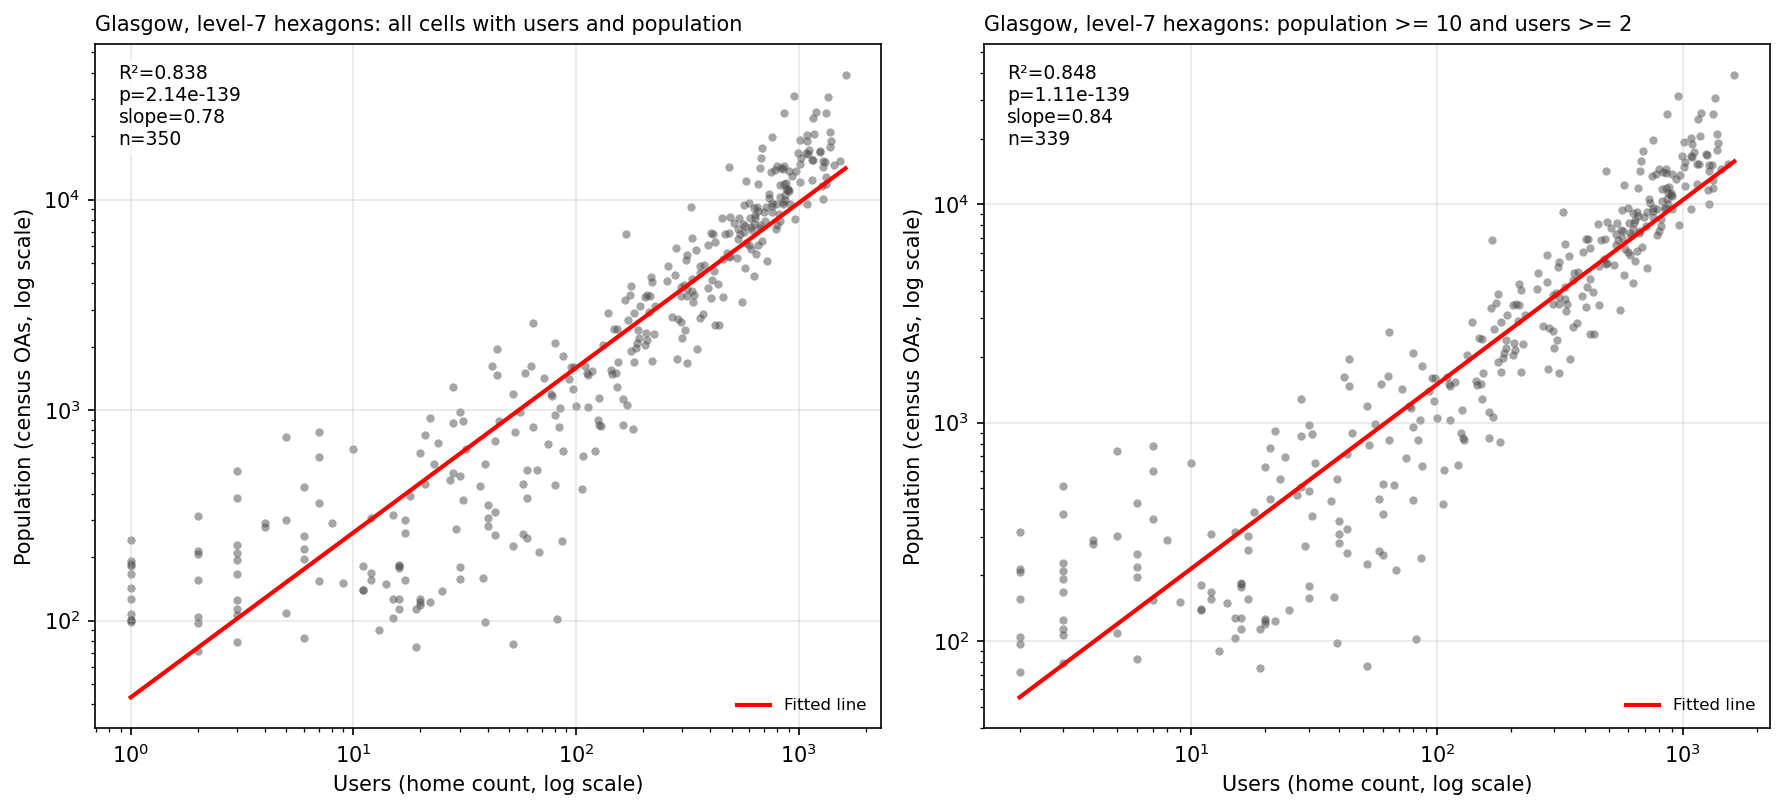

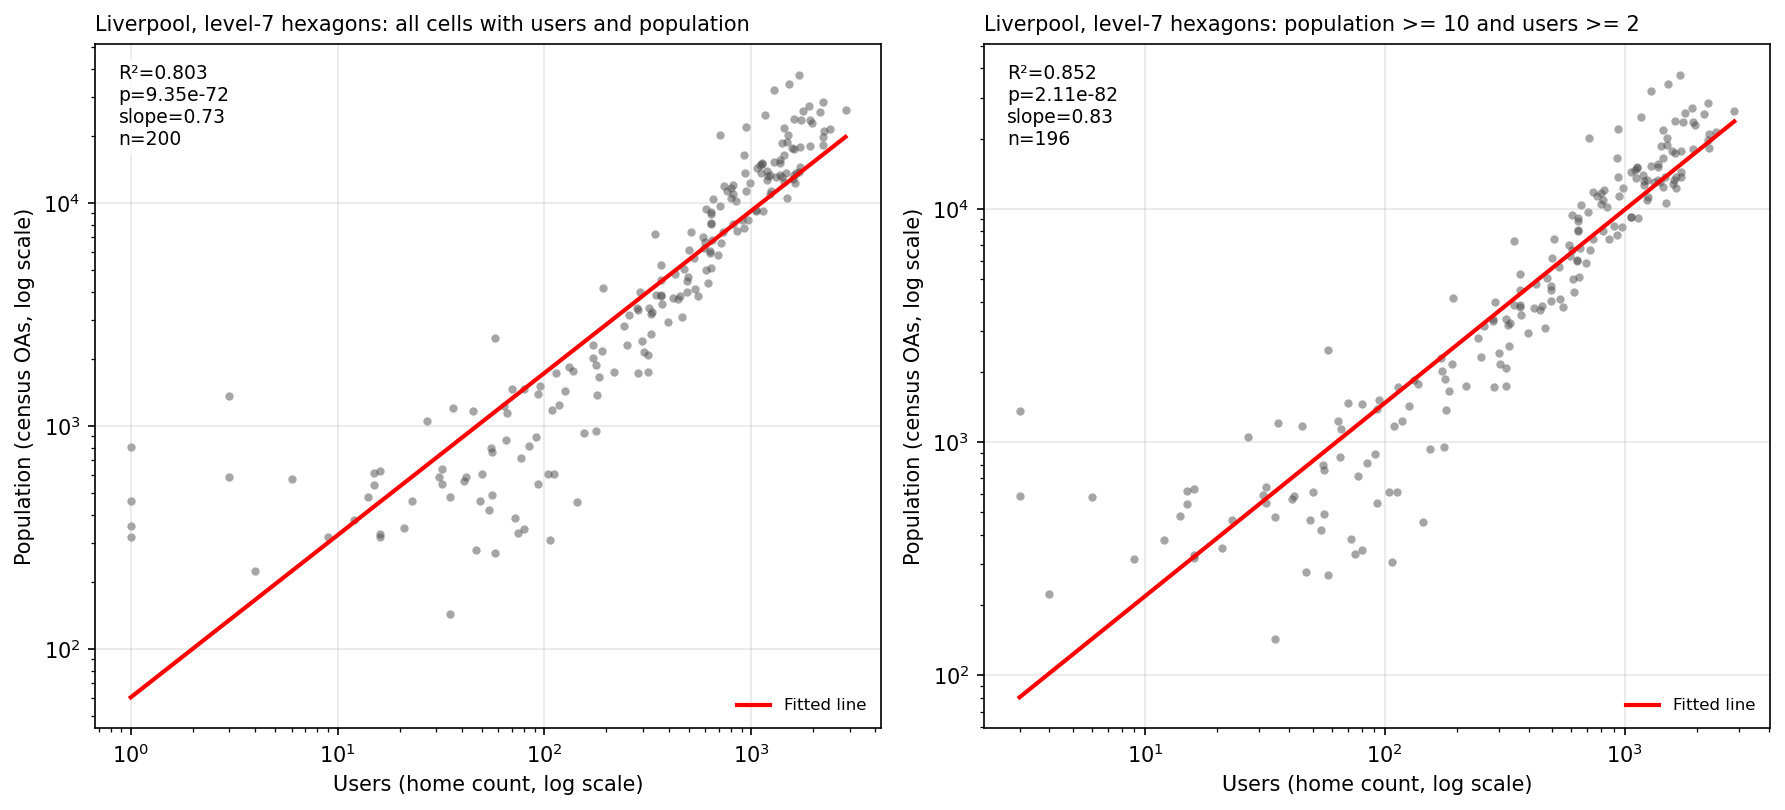

In [4]:
def loglog_panel(ax, g, title):
    lx, ly = np.log10(g.users_home_count.values), np.log10(g.population.values)
    res = linregress(lx, ly)
    ax.scatter(g.users_home_count, g.population, color="0.3", s=16, alpha=0.5, linewidths=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    lx_line = np.linspace(lx.min(), lx.max(), 200)
    ax.plot(10 ** lx_line, 10 ** (res.intercept + res.slope * lx_line), color="red", lw=2, label="Fitted line")
    ax.text(0.03, 0.97, f"R²={res.rvalue**2:.3f}\np={res.pvalue:.2e}\nslope={res.slope:.2f}\nn={len(g):,}", transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", alpha=0.7, lw=0))
    ax.set_xlabel("Users (home count, log scale)"); ax.set_ylabel("Population (census OAs, log scale)"); ax.set_title(title, fontsize=10, loc="left")
    ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=8)
    return res

FITS = {}
for res in UNITS:
    for key in CITY_KEYS:
        name = CITIES[key]["name"]; g = G[(key, res)]
        g_all = g.query("users_home_count > 0 and population > 0")
        g_5   = g.query(f"population >= {POP_MIN} and users_home_count >= {USERS_MIN}")
        fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), dpi=FIGURE_DPI)
        FITS[(key, res)] = {"all": loglog_panel(axes[0], g_all, f"{name}, level-{res} hexagons: all cells with users and population"),
                            "pop>=5": loglog_panel(axes[1], g_5, f"{name}, level-{res} hexagons: population >= {POP_MIN} and users >= {USERS_MIN}")}
        plt.tight_layout(); plt.show()


## 4. Penetration per hexagon and summary

In [5]:
def poisson_ceiling(g, n_sim=20, seed=0):
    """R² (filtered fit) that a perfectly proportional sample of the same size would give: users ~ Poisson(penetration x population)"""
    rng = np.random.default_rng(seed); p = g.population.values.astype(float); pen = g.users_home_count.sum() / p.sum(); out = []
    for _ in range(n_sim):
        u = rng.poisson(pen * p).astype(float); m = (p >= POP_MIN) & (u >= USERS_MIN)
        out.append(linregress(np.log10(u[m]), np.log10(p[m])).rvalue ** 2)
    return float(np.mean(out))

rows = []
for res in UNITS:
    for key in CITY_KEYS:
        g = G[(key, res)]; g5 = g.query(f"population >= {POP_MIN} and users_home_count >= {USERS_MIN}").copy(); g5["penetration"] = g5.users_home_count / g5.population
        f_all, f_5 = FITS[(key, res)]["all"], FITS[(key, res)]["pop>=5"]
        rows.append({"city": CITIES[key]["name"], "unit": unit_label(res), "mean cell area km²": g.area_km2.mean(), "population source": POP_SOURCE,
                     "census population (hexagons of the FUA)": int(g.population.sum()), "sample users": int(g.users_home_count.sum()),
                     "overall penetration %": 100 * g.users_home_count.sum() / g.population.sum(),
                     "hexagons with population": int((g.population > 0).sum()), "hexagons with users": int((g.users_home_count > 0).sum()),
                     "population in hexagons without users %": 100 * g.loc[g.users_home_count == 0, "population"].sum() / g.population.sum(),
                     "R² all cells": f_all.rvalue ** 2, "slope all cells": f_all.slope,
                     f"R² pop>={POP_MIN} & users>={USERS_MIN}": f_5.rvalue ** 2, f"slope pop>={POP_MIN} & users>={USERS_MIN}": f_5.slope, f"n cells pop>={POP_MIN} & users>={USERS_MIN}": len(g5),
                     "R² ceiling of a proportional Poisson sample": poisson_ceiling(g),
                     f"mean penetration (pop>={POP_MIN} & users>={USERS_MIN})": g5.penetration.mean(), f"median penetration (pop>={POP_MIN} & users>={USERS_MIN})": g5.penetration.median()})
summary = pd.DataFrame(rows).set_index(["city", "unit"])
summary.round(4).T


city,London,Manchester,Birmingham,Glasgow,Liverpool,London,Manchester,Birmingham,Glasgow,Liverpool
unit,H3 level 8,H3 level 8,H3 level 8,H3 level 8,H3 level 8,H3 level 7,H3 level 7,H3 level 7,H3 level 7,H3 level 7
mean cell area km²,0.6582,0.6579,0.6644,0.6445,0.6623,4.6036,4.6087,4.649,4.5105,4.6341
population source,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3,ONS Census 2021 / NRS Census 2022 OAs -> H3
census population (hexagons of the FUA),12366348,3423655,3136409,1839683,1537674,12408627,3402451,3136517,1785369,1540551
sample users,1230667,320454,295117,129747,129464,1262729,324150,301146,127928,132830
overall penetration %,9.9517,9.36,9.4094,7.0527,8.4195,10.1762,9.527,9.6013,7.1654,8.6222
hexagons with population,5492,2190,1748,1390,903,1353,529,411,389,205
hexagons with users,4906,1894,1553,1224,794,1334,488,396,350,200
population in hexagons without users %,1.6311,2.8675,2.207,1.3048,2.2892,0.0636,0.395,0.1716,0.3258,0.135
R² all cells,0.6221,0.5996,0.6203,0.6451,0.6108,0.8467,0.8294,0.8707,0.8376,0.8029


In [6]:
# Robustness: the log-log fit under stricter cuts on small counts, each against the R² a proportional Poisson sample would give
CUTS = {"all cells (users > 0, pop > 0)": (1, 1), "pop >= 5, users >= 1 (Finnish paper)": (5, 1), "pop >= 10, users >= 2 (headline)": (10, 2),
        "pop >= 50, users >= 5": (50, 5), "pop >= 100, users >= 10": (100, 10)}

def fit_r2(u, p, pm, um):
    m = (p >= pm) & (u >= um)
    if m.sum() < 3 or np.ptp(u[m]) == 0:                      # a cut that leaves too few cells for a fit
        return np.nan, np.nan, int(m.sum())
    res = linregress(np.log10(u[m]), np.log10(p[m])); return res.rvalue ** 2, res.slope, int(m.sum())

def ceiling(p, pen, pm, um, n_sim=20, seed=0):
    rng = np.random.default_rng(seed)
    return float(np.nanmean([fit_r2(rng.poisson(pen * p).astype(float), p, pm, um)[0] for _ in range(n_sim)]))

rob = []
for res in UNITS:
    for key in CITY_KEYS:
        g = G[(key, res)]; u, p = g.users_home_count.values.astype(float), g.population.values.astype(float); pen = u.sum() / p.sum()
        for cut, (pm, um) in CUTS.items():
            r2, slope, n = fit_r2(u, p, pm, um); c = ceiling(p, pen, pm, um)
            rob.append({"city": CITIES[key]["name"], "unit": unit_label(res), "cut": cut, "n cells": n, "R²": r2, "R² Poisson ceiling": c, "ratio": r2 / c, "slope": slope})
robust = pd.DataFrame(rob).set_index(["city", "unit", "cut"])
robust.round(3)


n cells     R²  \
city       unit       cut                                                    
London     H3 level 8 all cells (users > 0, pop > 0)           4906  0.622   
                      pop >= 5, users >= 1 (Finnish paper)     4906  0.622   
                      pop >= 10, users >= 2 (headline)         4804  0.654   
                      pop >= 50, users >= 5                    4677  0.676   
                      pop >= 100, users >= 10                  4541  0.687   
Manchester H3 level 8 all cells (users > 0, pop > 0)           1894  0.600   
                      pop >= 5, users >= 1 (Finnish paper)     1894  0.600   
                      pop >= 10, users >= 2 (headline)         1846  0.621   
                      pop >= 50, users >= 5                    1795  0.633   
                      pop >= 100, users >= 10                  1739  0.639   
Birmingham H3 level 8 all cells (users > 0, pop > 0)           1553  0.620   
                      pop >= 5, users >= 1 (Finnish paper)     1553  0.620   
                      pop >= 10, users >= 2 (headline)         1519  0.633   
                      pop >= 50, users >= 5                    1479  0.639   
                      pop >= 100, users >= 10                  1432  0.630   
Glasgow    H3 level 8 all cells (users > 0, pop > 0)           1224  0.645   
                      pop >= 5, users >= 1 (Finnish paper)     1224  0.645   
                      pop >= 10, users >= 2 (headline)         1197  0.637   
                      pop >= 50, users >= 5                    1156  0.625   
                      pop >= 100, users >= 10                  1090  0.616   
Liverpool  H3 level 8 all cells (users > 0, pop > 0)            794  0.611   
                      pop >= 5, users >= 1 (Finnish paper)      794  0.611   
                      pop >= 10, users >= 2 (headline)          780  0.636   
                      pop >= 50, users >= 5                     761  0.657   
                      pop >= 100, users >= 10                   741  0.662   
London     H3 level 7 all cells (users > 0, pop > 0)           1334  0.847   
                      pop >= 5, users >= 1 (Finnish paper)     1334  0.847   
                      pop >= 10, users >= 2 (headline)         1327  0.857   
                      pop >= 50, users >= 5                    1305  0.874   
                      pop >= 100, users >= 10                  1273  0.887   
Manchester H3 level 7 all cells (users > 0, pop > 0)            488  0.829   
                      pop >= 5, users >= 1 (Finnish paper)      488  0.829   
                      pop >= 10, users >= 2 (headline)          476  0.875   
                      pop >= 50, users >= 5                     462  0.903   
                      pop >= 100, users >= 10                   452  0.905   
Birmingham H3 level 7 all cells (users > 0, pop > 0)            396  0.871   
                      pop >= 5, users >= 1 (Finnish paper)      396  0.871   
                      pop >= 10, users >= 2 (headline)          393  0.886   
                      pop >= 50, users >= 5                     386  0.898   
                      pop >= 100, users >= 10                   378  0.903   
Glasgow    H3 level 7 all cells (users > 0, pop > 0)            350  0.838   
                      pop >= 5, users >= 1 (Finnish paper)      350  0.838   
                      pop >= 10, users >= 2 (headline)          339  0.848   
                      pop >= 50, users >= 5                     320  0.860   
                      pop >= 100, users >= 10                   302  0.885   
Liverpool  H3 level 7 all cells (users > 0, pop > 0)            200  0.803   
                      pop >= 5, users >= 1 (Finnish paper)      200  0.803   
                      pop >= 10, users >= 2 (headline)          196  0.852   
                      pop >= 50, users >= 5                     193  0.887   
                      pop >= 100, users >= 10                   191  0.895   

   

In [7]:
def merge_save(df, path):
    """rows of the cities of this run replace the rows of the same cities in the saved file; other cities are kept"""
    if path.exists():
        old = pd.read_csv(path); old = old[~old.city.isin(df.index.get_level_values("city"))]
        df = pd.concat([old.set_index(df.index.names), df]).reindex(columns=df.columns)
        order = {CITIES[k]["name"]: i for i, k in enumerate(ALL_CITY_KEYS)}
        df = df.reset_index().assign(_o=lambda d: d.city.map(order)).sort_values("_o", kind="stable").drop(columns="_o").set_index(df.index.names)
    df.to_csv(path)
    return df

saved = {}
for res in UNITS:
    s = summary[summary.index.get_level_values("unit") == unit_label(res)]; r = robust[robust.index.get_level_values("unit") == unit_label(res)]
    saved[res] = merge_save(s, SCRATCH / "results" / f"representation_hex{res}_summary_GBR_{PERIOD}.csv")
    merge_save(r, SCRATCH / "results" / f"representation_hex{res}_robustness_GBR_{PERIOD}.csv")
    for key in CITY_KEYS:
        G[(key, res)].rename(columns={"cell": f"h3_{res}"}).to_csv(SCRATCH / "results" / CITIES[key]["country"] / f"{key}_{PERIOD}" / f"representation_hex{res}.csv", index=False)
    print(f"saved: representation_hex{res}_summary_GBR ({len(saved[res])} rows), representation_hex{res}_robustness_GBR and one representation_hex{res}.csv per city")

pd.concat(saved.values())[["mean cell area km²", "census population (hexagons of the FUA)", "sample users", "overall penetration %", f"R² pop>={POP_MIN} & users>={USERS_MIN}",
             f"slope pop>={POP_MIN} & users>={USERS_MIN}", "R² ceiling of a proportional Poisson sample", f"median penetration (pop>={POP_MIN} & users>={USERS_MIN})"]].round(3)


saved: representation_hex8_summary_GBR (5 rows), representation_hex8_robustness_GBR and one representation_hex8.csv per city
saved: representation_hex7_summary_GBR (5 rows), representation_hex7_robustness_GBR and one representation_hex7.csv per city


,,mean cell area km²,census population (hexagons of the FUA),sample users,overall penetration %,R² pop>=10 & users>=2,slope pop>=10 & users>=2,R² ceiling of a proportional Poisson sample,median penetration (pop>=10 & users>=2)
city,unit,,,,,,,,
London,H3 level 8,0.658,12366348,1230667,9.952,0.654,0.654,0.989,0.106
Manchester,H3 level 8,0.658,3423655,320454,9.360,0.621,0.566,0.982,0.093
Birmingham,H3 level 8,0.664,3136409,295117,9.409,0.633,0.597,0.985,0.094
Glasgow,H3 level 8,0.644,1839683,129747,7.053,0.637,0.686,0.972,0.070
Liverpool,H3 level 8,0.662,1537674,129464,8.419,0.636,0.602,0.982,0.085
London,H3 level 7,4.604,12408627,1262729,10.176,0.857,0.827,0.996,0.122
Manchester,H3 level 7,4.609,3402451,324150,9.527,0.875,0.787,0.995,0.096
Birmingham,H3 level 7,4.649,3136517,301146,9.601,0.886,0.845,0.996,0.101
Glasgow,H3 level 7,4.511,1785369,127928,7.165,0.848,0.844,0.988,0.076


## Notes

- `boundaries/uk_oa/` on scratch holds the inputs: `census2021-ts001.zip` (ONS bulk TS001, `oa2021_ew_population_ts001.csv` extracted from it),
  `oa2021_ew_boundary_centroids_bgc.csv` (BNG centroid fields of the ONS `OA_2021_EW_BGC_V2` layer, read through its REST query endpoint),
  `output-area-2022-pwc.zip` and `outputarea2022_usualresidentpopulation.csv` (NRS; the `Popcount` field inside the shapefile is a preliminary
  count 2% below the published CSV, the CSV is used), and the derived `uk_oa_population_centroids.parquet` (built 2026-11-23: reproject the
  centroids to WGS84, one row per OA with lon/lat and population). The OA-to-hexagon assignment is done in this notebook for each resolution
  with `h3.latlng_to_cell`.
- H3 cells shrink towards the poles: at the latitude of the British cities a level-8 hexagon is about 0.65 km² (global mean 0.74) and a level-7
  hexagon about 4.6 km² (global mean 5.16), so level 7 is the closest H3 match to the 2 km (4 km²) square used for the German and French cities.
- Census populations inside the FUAs are 0.5–3% above the JRC-GEOSTAT 2018 grid used by the square-grid version, consistent with population
  growth 2018–2021/22.
- Run as a batch job from `roihu-cpu.csc.fi` on a full node (the two level-8 UK tables are 38 and 44 GB; about 10 min):

```bash
sbatch --account=project_2022768 --partition=small --time=01:00:00 --nodes=1 --ntasks=1 --cpus-per-task=384 --mem=700G --job-name=representation_hex_GBR \
  --export=ALL,LOCO_LOCAL_WORK=1 --output=/scratch/project_2022768/%u/locomizer/logs/representation_hex_GBR_%j.out \
  --wrap="module load python-geo; cd ~/locomizer_signals/representation; jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 representation_uk_hex8.ipynb"
```
